# TKS Replicate mini-project: visual-category ERP comparison

**Question.** For one participant in Kaneshiro et al. (2015), do the average post-stimulus EEG traces differ descriptively across a small, fixed sample of visual categories?

**Scope.** This notebook loads the `Kaneshiro2015` MOABB dataset, reconstructs stimulus-locked epochs, caps the analysis at 60 trials in each of three categories, and plots posterior-sensor ERPs. It deliberately contains **no classifier or machine learning**.

The source data are already processed (1–25 Hz filtering, ICA cleaning, average reference and 62.5 Hz sampling) and span 0–496 ms after stimulus onset. There is no prestimulus baseline in this release, so the plots are un-baselined and should be interpreted as descriptive.

**Sources:** Kaneshiro et al. (2015), doi:10.1371/journal.pone.0135697; [MOABB dataset documentation](https://moabb.neurotechx.com/docs/generated/moabb.datasets.Kaneshiro2015.html).

In [ ]:
# Colab setup — run once. The dataset download for one participant is about 316 MB.
%pip -q install "moabb>=1.7.2" "mne>=1.10" "matplotlib>=3.6"


In [2]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from moabb.datasets import Kaneshiro2015

# Reproducible choices for a compact descriptive analysis.
SUBJECT = 1
CATEGORIES = ["human_face", "animal_face", "inanimate_object"]
TRIALS_PER_CATEGORY = 60
TMIN, TMAX = 0.0, 0.496
DATA_DIR = Path.cwd() / "moabb_data"
DATA_DIR.mkdir(exist_ok=True)
os.environ["MNE_DATA"] = str(DATA_DIR)
# Pin the downloader to the original public participant file: only one subject is needed.
os.environ["MOABB_DOWNLOAD_PROVIDER"] = "upstream"

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

/private/tmp/tks_erp_venv_312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# MOABB downloads the public S1.mat file on first run, then reconstructs an MNE Raw object.
dataset = Kaneshiro2015()
data = dataset.get_data(subjects=[SUBJECT])
raw = next(iter(next(iter(data[SUBJECT].values())).values()))

print(raw)
print("Event labels:", dataset.event_id)
print(f"Sampling rate: {raw.info['sfreq']} Hz | EEG channels: {len(mne.pick_types(raw.info, eeg=True))}")

<RawArray | 125 x 197144 (3154.3 s), ~188.1 MiB, data loaded>
Event labels: {'human_body': 1, 'human_face': 2, 'animal_body': 3, 'animal_face': 4, 'fruit_vegetable': 5, 'inanimate_object': 6}
Sampling rate: 62.5 Hz | EEG channels: 124


In [4]:
# Convert the reconstructed stimulus channel into the original 0–496 ms epochs.
events = mne.find_events(raw, stim_channel="STI", shortest_event=1, initial_event=True, verbose=False)
epochs = mne.Epochs(
    raw, events, event_id=dataset.event_id, tmin=TMIN, tmax=TMAX,
    baseline=None, preload=True, reject_by_annotation=False, verbose=False,
)

available = pd.Series({category: len(epochs[category]) for category in CATEGORIES}, name="available trials")
print(f"Epoch array: {epochs.get_data().shape}  # trials × channels × time points")
display(available.to_frame())

Epoch array: (5188, 125, 32)  # trials × channels × time points


,available trials
human_face,864
animal_face,865
inanimate_object,864


Posterior ROI (20 sensors): ['E75', 'E74', 'E82', 'E70', 'E83', 'E81', 'E71', 'E76', 'E73', 'E88', 'E69', 'E89', 'E72', 'E66', 'E84', 'E65', 'E90', 'E68', 'E94', 'E67']


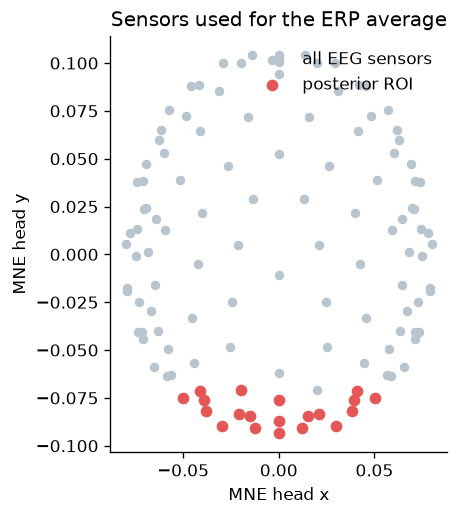

In [5]:
# Use the 20 most posterior electrodes from the recorded HydroCel montage.
# In MNE head coordinates, smaller y is more posterior; the plot makes the selection explicit.
montage_positions = raw.get_montage().get_positions()["ch_pos"]
eeg_names = [raw.ch_names[i] for i in mne.pick_types(raw.info, eeg=True)]
posterior_roi = sorted(eeg_names, key=lambda name: montage_positions[name][1])[:20]
print("Posterior ROI (20 sensors):", posterior_roi)

all_xy = np.array([[montage_positions[name][0], montage_positions[name][1]] for name in eeg_names])
roi_xy = np.array([[montage_positions[name][0], montage_positions[name][1]] for name in posterior_roi])
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(all_xy[:, 0], all_xy[:, 1], s=22, color="#b8c4ce", label="all EEG sensors")
ax.scatter(roi_xy[:, 0], roi_xy[:, 1], s=36, color="#e45756", label="posterior ROI")
ax.set(title="Sensors used for the ERP average", xlabel="MNE head x", ylabel="MNE head y", aspect="equal")
ax.legend(frameon=False, loc="upper right")
plt.show()

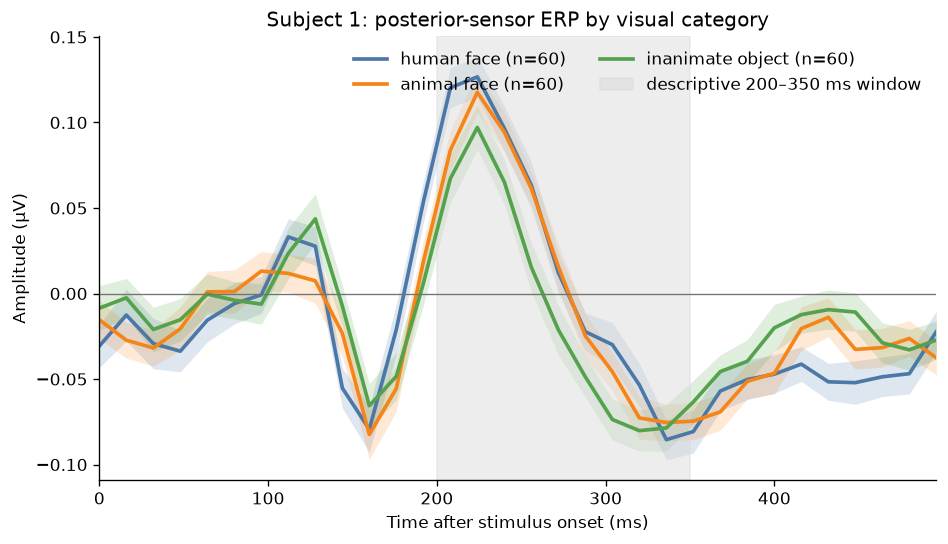

In [6]:
# Fixed first-N cap keeps this a small, reproducible sample rather than a full-dataset analysis.
times_ms = epochs.times * 1_000
erp = {}
trial_traces = {}
for category in CATEGORIES:
    selected = epochs[category][:TRIALS_PER_CATEGORY]
    # Convert V to µV; average sensors inside a trial before estimating trial-wise SEM.
    traces_uv = selected.get_data(picks=posterior_roi).mean(axis=1) * 1e6
    trial_traces[category] = traces_uv
    erp[category] = {
        "n": len(selected),
        "mean": traces_uv.mean(axis=0),
        "sem": traces_uv.std(axis=0, ddof=1) / np.sqrt(len(selected)),
    }

colors = {"human_face": "#4c78a8", "animal_face": "#f58518", "inanimate_object": "#54a24b"}
fig, ax = plt.subplots(figsize=(9, 4.8))
for category in CATEGORIES:
    mean, sem, n = erp[category]["mean"], erp[category]["sem"], erp[category]["n"]
    ax.plot(times_ms, mean, lw=2.2, color=colors[category], label=f"{category.replace('_', ' ')} (n={n})")
    ax.fill_between(times_ms, mean - sem, mean + sem, color=colors[category], alpha=0.18, linewidth=0)
ax.axhline(0, color="0.45", lw=0.8)
ax.axvspan(200, 350, color="0.85", alpha=0.45, label="descriptive 200–350 ms window")
ax.set(
    title=f"Subject {SUBJECT}: posterior-sensor ERP by visual category",
    xlabel="Time after stimulus onset (ms)", ylabel="Amplitude (µV)", xlim=(0, 496),
)
ax.legend(frameon=False, ncols=2)
plt.show()

In [7]:
# Compact, data-derived summary — do not treat these as inferential tests.
window = (epochs.times >= 0.200) & (epochs.times <= 0.350)
rows = []
for category in CATEGORIES:
    mean_trace = erp[category]["mean"]
    peak_index = np.abs(mean_trace).argmax()
    rows.append({
        "category": category,
        "trials used": erp[category]["n"],
        "mean 200–350 ms (µV)": mean_trace[window].mean(),
        "largest |mean| time (ms)": times_ms[peak_index],
        "amplitude at that time (µV)": mean_trace[peak_index],
    })
summary = pd.DataFrame(rows).set_index("category").round(3)
display(summary)

print("Reading this output:")
print("• Compare curve shape, uncertainty bands, and the descriptive table; do not infer category selectivity from one subject.")
print("• A nonzero value at 0 ms is not a baseline offset to remove here: the published epochs contain no prestimulus segment.")
print("• A follow-up would repeat this for the other participants, predefine sensors/time windows, and use a suitable repeated-measures statistical plan.")

,trials used,mean 200–350 ms (µV),largest |mean| time (ms),amplitude at that time (µV)
category,,,,
human_face,60,0.025,224.0,0.127
animal_face,60,0.017,224.0,0.118
inanimate_object,60,-0.006,224.0,0.097


Reading this output:
• Compare curve shape, uncertainty bands, and the descriptive table; do not infer category selectivity from one subject.
• A nonzero value at 0 ms is not a baseline offset to remove here: the published epochs contain no prestimulus segment.
• A follow-up would repeat this for the other participants, predefine sensors/time windows, and use a suitable repeated-measures statistical plan.


## Findings and limitations

After execution, the figure and table are the project’s findings for this small sample: they report the observed condition averages and uncertainty without overclaiming an effect. The original study reports that human-face responses were particularly distinct in its category-level analyses, but this notebook does **not** reproduce that classification/RSA work and should not be used to claim it has.

Key limitations:

- One participant and 60 chronological trials per condition: this is illustrative, not population evidence.
- The data arrive already processed and begin at stimulus onset, so filtering, artefact decisions and prestimulus baseline correction cannot be independently audited here.
- The posterior ROI is a transparent heuristic based on sensor positions, not an individually localized visual-cortex measure.
- SEM bands describe variation of sampled trials in this participant; they are not confidence intervals for a category effect and no statistical test is performed.

**Reproducibility:** rerunning with the same package versions, `SUBJECT`, categories and trial cap yields the same selection. To extend responsibly, change one design choice at a time and document it.